<img src="./assets/ga-logo.png" style="float: left; margin: 20px; height: 55px">

# Lab: Supervised Learning Model Comparison
---

Recall the data science process.

1. Define the problem.
2. Gather the data.
3. Explore the data.
4. Model the data.
5. Evaluate the model.
6. Answer the problem.

In this lab, we're going to focus mostly on creating (and then comparing) many regression and classification models. Thus, we'll define the problem and gather the data for you.
Most of the questions requiring a written response can be written in 2-3 sentences.

### Step 1: Define the problem.

You are a data scientist with a financial services company. Specifically, you want to leverage data in order to identify potential customers.

If you are unfamiliar with "401(k)s" or "IRAs," these are two types of retirement accounts. Very broadly speaking:
- You can put money for retirement into both of these accounts.
- The money in these accounts gets invested and hopefully has a lot more money in it when you retire.
- These are a little different from regular bank accounts in that there are certain tax benefits to these accounts. Also, employers frequently match money that you put into a 401k.
- If you want to learn more about them, check out [this site](https://www.nerdwallet.com/article/ira-vs-401k-retirement-accounts).

We will tackle one regression problem and one classification problem today.
- Regression: What features best predict one's income?
- Classification: Predict whether or not one is eligible for a 401k.

Check out the data dictionary [here](http://fmwww.bc.edu/ec-p/data/wooldridge2k/401KSUBS.DES).

### NOTE: When predicting `inc`, you should pretend as though you do not have access to the `e401k`, the `p401k` variable, and the `pira` variable. When predicting `e401k`, you may use the entire dataframe if you wish.

In [1]:
import numpy as np
import pandas as pd

### Step 2: Gather the data.

##### 1. Read in the data from the repository.

In [2]:
df = pd.read_csv("data/401ksubs.csv")

In [3]:
df.describe()

,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
count,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000,9275.000000
mean,0.392129,39.254641,0.628571,0.204420,41.080216,2.885067,19.071675,0.276226,0.254340,2121.192483,1793.652722
std,0.488252,24.090002,0.483213,0.403299,10.299517,1.525835,63.963838,0.447154,0.435513,3001.469424,895.648841
min,0.000000,10.008000,0.000000,0.000000,25.000000,1.000000,-502.302000,0.000000,0.000000,100.160100,625.000000
25%,0.000000,21.660000,0.000000,0.000000,33.000000,2.000000,-0.500000,0.000000,0.000000,469.155600,1089.000000
50%,0.000000,33.288000,1.000000,0.000000,40.000000,3.000000,2.000000,0.000000,0.000000,1108.091000,1600.000000
75%,1.000000,50.160000,1.000000,0.000000,48.000000,4.000000,18.449500,1.000000,1.000000,2516.025500,2304.000000
max,1.000000,199.041000,1.000000,1.000000,64.000000,13.000000,1536.798000,1.000000,1.000000,39617.320000,4096.000000


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9275 entries, 0 to 9274
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   e401k   9275 non-null   int64  
 1   inc     9275 non-null   float64
 2   marr    9275 non-null   int64  
 3   male    9275 non-null   int64  
 4   age     9275 non-null   int64  
 5   fsize   9275 non-null   int64  
 6   nettfa  9275 non-null   float64
 7   p401k   9275 non-null   int64  
 8   pira    9275 non-null   int64  
 9   incsq   9275 non-null   float64
 10  agesq   9275 non-null   int64  
dtypes: float64(3), int64(8)
memory usage: 797.2 KB


##### 2. What are 2-3 other variables that, if available, would be helpful to have?

In [5]:
# Maybe education, industry (type of employer e.g. government, academia, military...),
# and hours worked.

##### 3. Suppose a peer recommended putting `race` into your model in order to better predict who to target when advertising IRAs and 401(k)s. Why would this be an unethical decision?

In [6]:
# Using race would be unethical because it could result in discriminatory targeting and 
# reinforce unequal access to retirement savings opportunities. Financial advertising 
# should be based on relevant, non-protected characteristics and financial need, not race.

## Step 3: Explore the data.

##### 4. When attempting to predict income, which feature(s) would we reasonably not use? Why?

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

<Figure size 1600x1600 with 0 Axes>

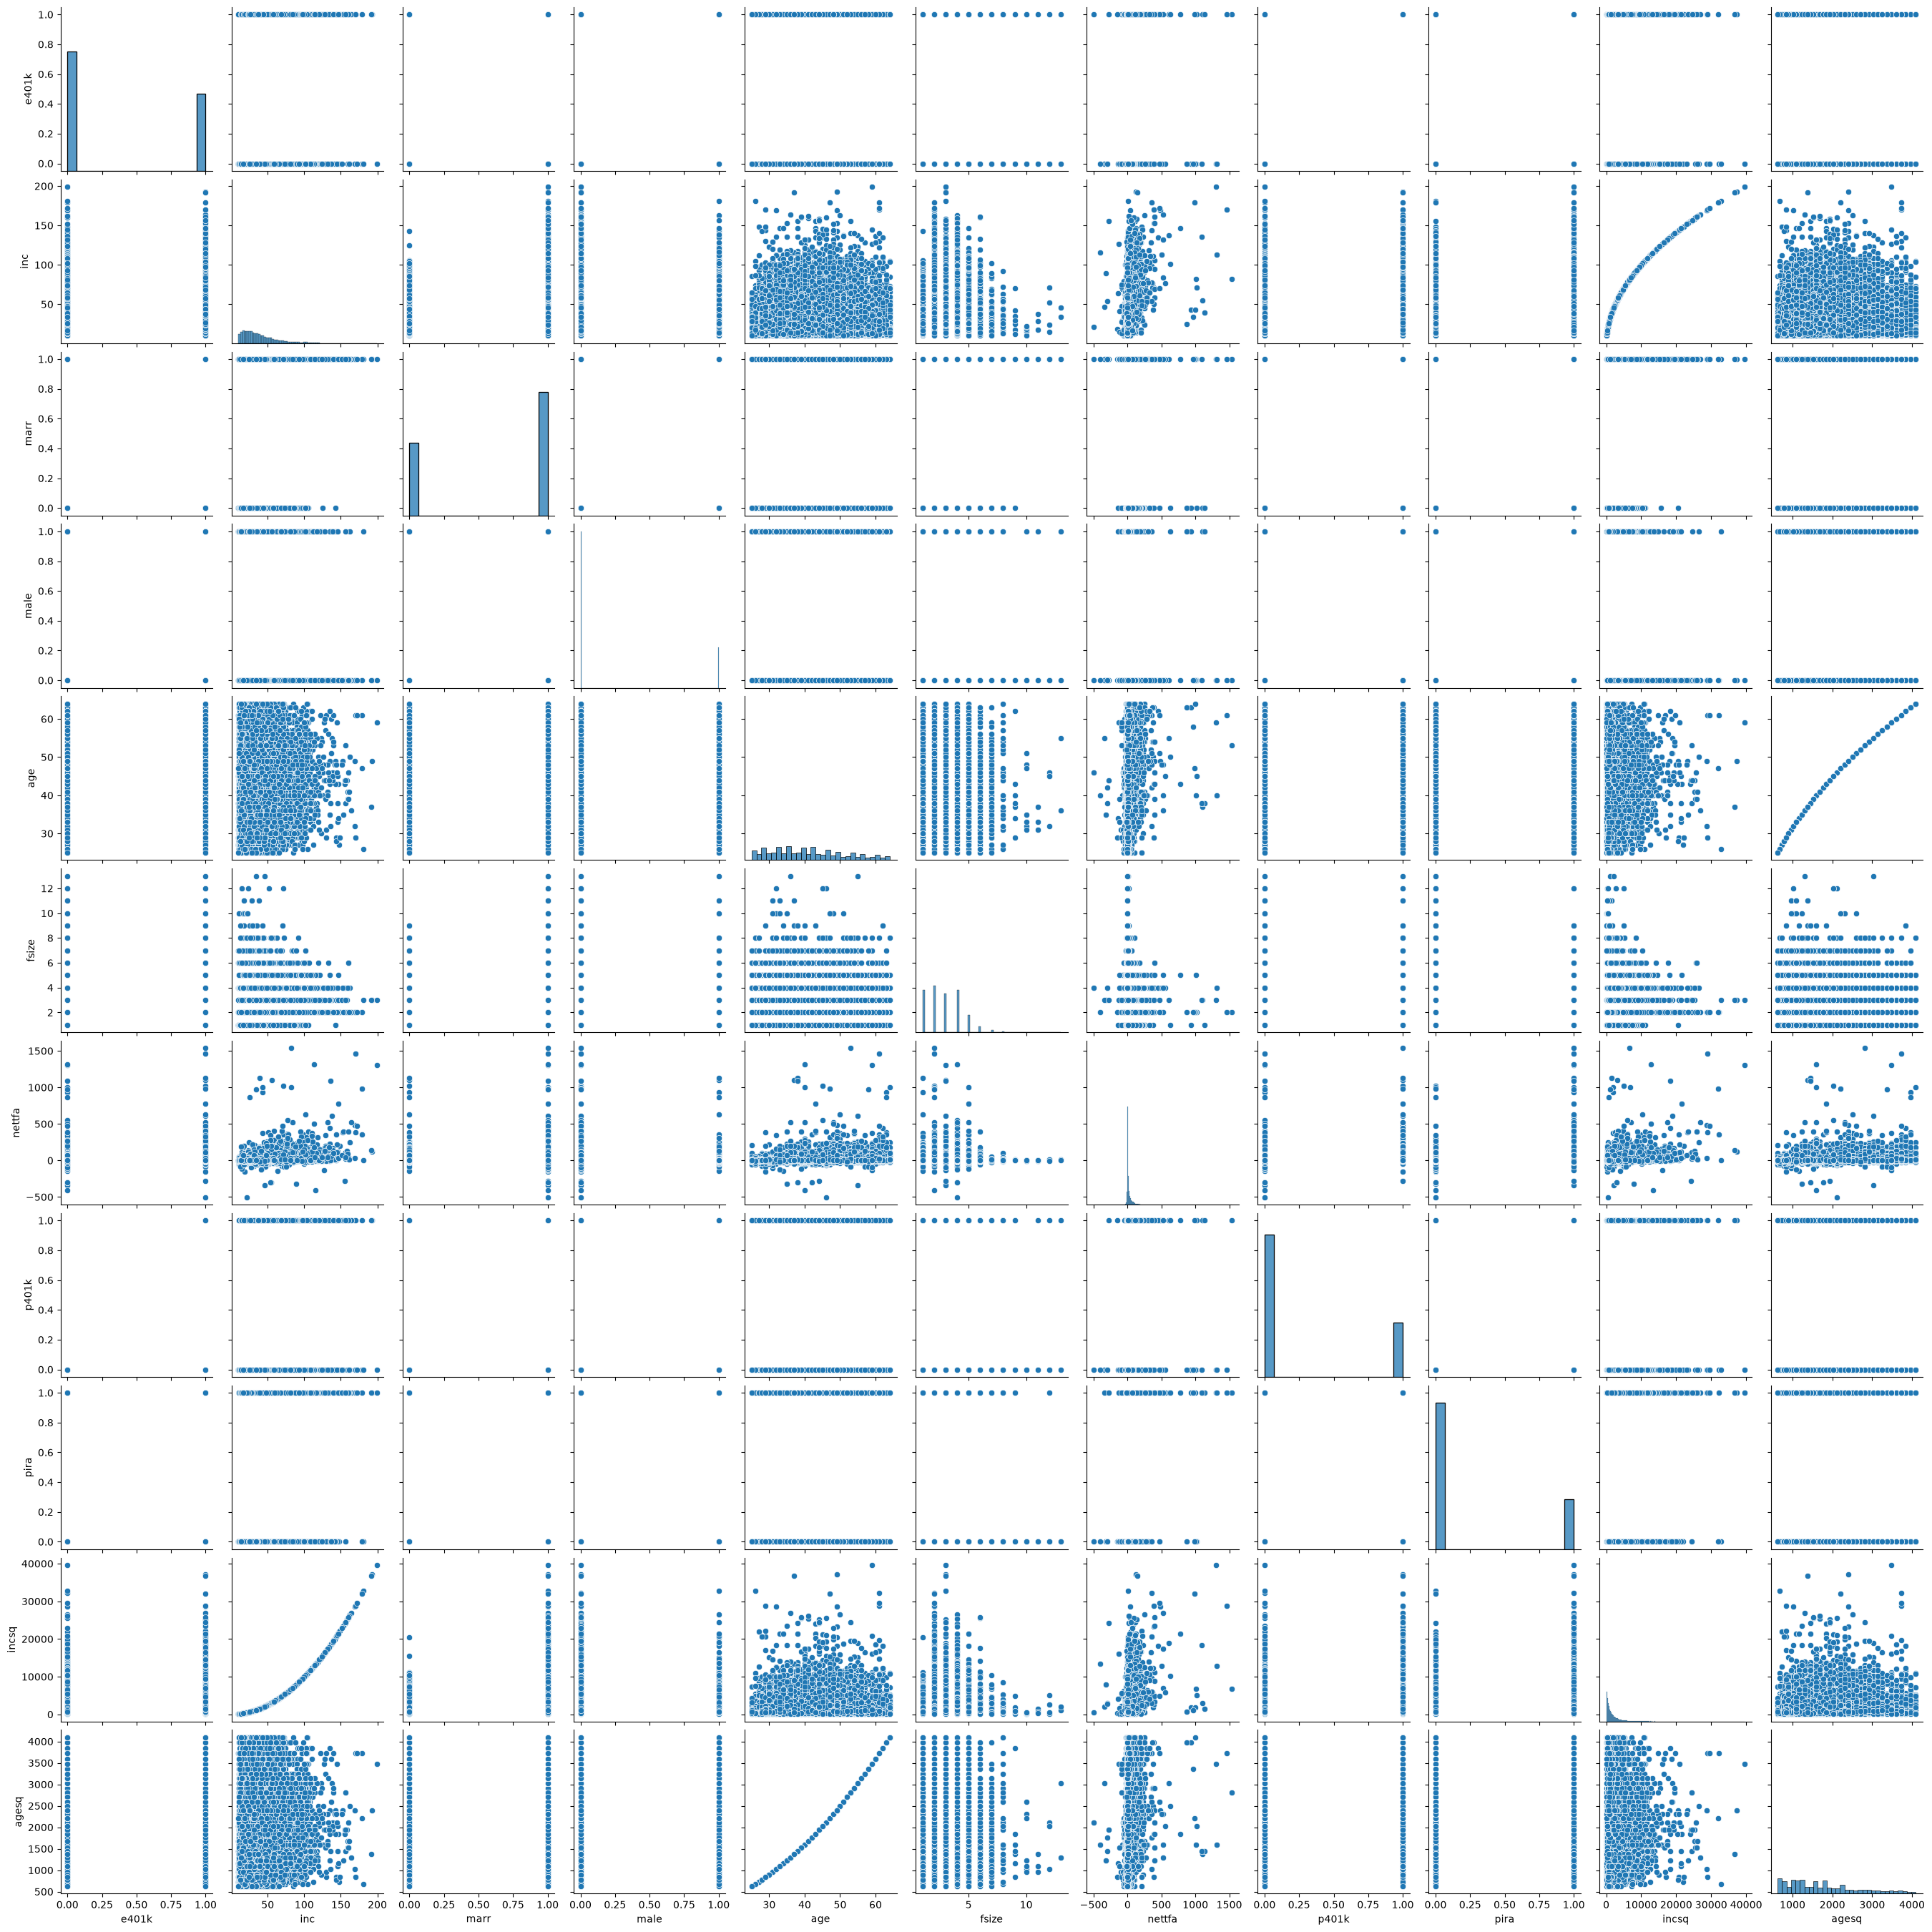

In [8]:
plt.figure(figsize=(16,16))
sns.pairplot(df);

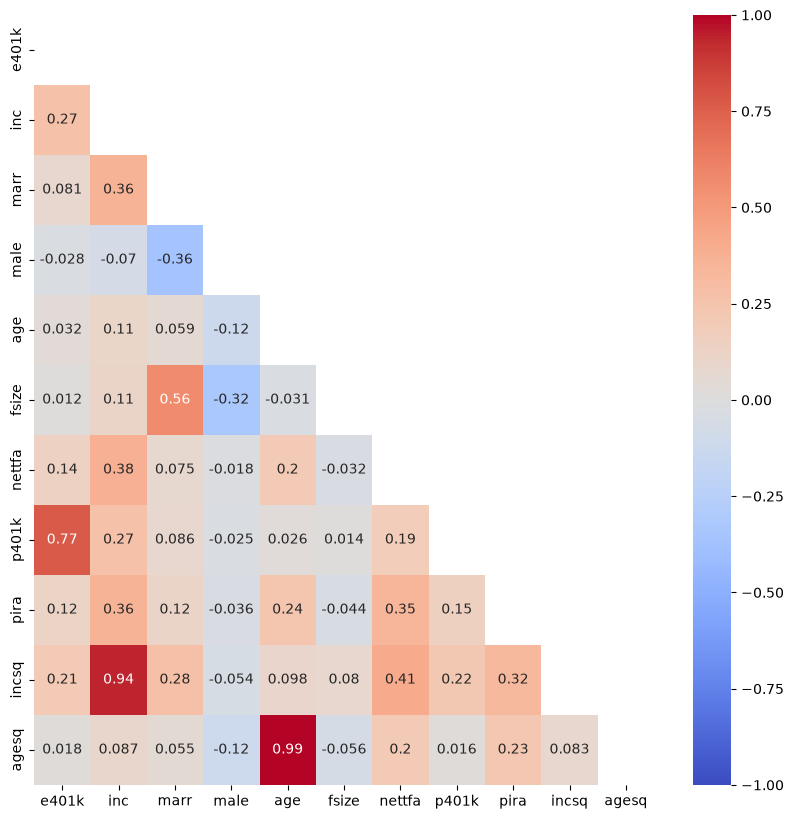

In [9]:
mask = np.zeros_like(df.corr())
mask[np.triu_indices_from(mask)] = True

plt.figure(figsize=(10, 10))
sns.heatmap(
    df.corr(),
    cmap='coolwarm',
    annot=True,
    mask = mask,
    vmin = -1,
    vmax = 1
);

In [10]:
df.head()

,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
0,0,13.170,0,0,40,1,4.575,0,1,173.4489,1600
1,1,61.230,0,1,35,1,154.000,1,0,3749.1130,1225
2,0,12.858,1,0,44,2,0.000,0,0,165.3282,1936
3,0,98.880,1,1,44,2,21.800,0,0,9777.2540,1936
4,0,22.614,0,0,53,1,18.450,0,0,511.3930,2809


In [11]:
# fsize, and maybe agesq as it is already related with the age

##### 5. What two variables have already been created for us through feature engineering? Come up with a hypothesis as to why subject-matter experts may have done this.
> This need not be a "statistical hypothesis." Just brainstorm why SMEs might have done this!

In [12]:
# agesq & incsq

## maybe to epnhasizes inc and age.

##### 6. Looking at the data dictionary, one variable description appears to be an error. What is this error, and what do you think the correct value would be?

In [13]:
#there are two errors in age and inc descriptions.

## Step 4: Model the data. (Part 1: Regression Problem)

Recall:
- Problem: What features best predict one's income?
- When predicting `inc`, you should pretend as though you do not have access to the `e401k`, the `p401k` variable, and the `pira` variable.

##### 7. List all modeling tactics we've learned that could be used to solve a regression problem (as of Wednesday afternoon of Week 6). For each tactic, identify whether it is or is not appropriate for solving this specific regression problem and explain why or why not.

In [14]:
# linear regression, single & multiple

##### 8. Regardless of your answer to number 7, fit at least one of each of the following models to attempt to solve the regression problem above:
    - a multiple linear regression model
    - a k-nearest neighbors model
    - a decision tree
    - a set of bagged decision trees
    - a random forest
    - an Adaboost model
    
> As always, be sure to do a train/test split! In order to compare modeling techniques, you should use the same train-test split on each. I recommend setting a random seed here.

> You may find it helpful to set up a pipeline to try each modeling technique, but you are not required to do so!

##### 9. What is bootstrapping?

##### 10. What is the difference between a decision tree and a set of bagged decision trees? Be specific and precise!

##### 11. What is the difference between a set of bagged decision trees and a random forest? Be specific and precise!

##### 12. Why might a random forest be superior to a set of bagged decision trees?
> Hint: Consider the bias-variance tradeoff.

## Step 5: Evaluate the model. (Part 1: Regression Problem)

##### 13. Using RMSE, evaluate each of the models you fit on both the training and testing data.

In [15]:
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

from sklearn import metrics
from sklearn.model_selection import train_test_split

In [16]:
df.columns

Index(['e401k', 'inc', 'marr', 'male', 'age', 'fsize', 'nettfa', 'p401k',
       'pira', 'incsq', 'agesq'],
      dtype='str')

In [17]:
X = df[[ 'marr', 'male', 'age', 'fsize', 'nettfa', 'agesq'
        #'e401k','p401k','pira'
        ]]
y = df['inc']

X_train, X_test, y_train, y_test = train_test_split(X,y, random_state=42)
lr = LinearRegression()

In [18]:
for column in X_train.columns:

    lr.fit(X_train[[column]], y_train)
    y_pred = lr.predict(X_test[[column]])
    y_pred_train = lr.predict(X_train[[column]])

    rmse_test = metrics.root_mean_squared_error(y_pred, y_test)
    rmse_train = metrics.root_mean_squared_error(y_pred_train, y_train)
   
    r2_test = metrics.r2_score(y_test, y_pred)
    r2_train = metrics.r2_score(y_train, y_pred_train)

    print('*****************************************************************')    
    print("For the column %s, metrics are: rmse_train: %.2f, rmse_test: %.2f, r2_train: %.2f, r2_test: %.2f" %(column, rmse_train, rmse_test, r2_train, r2_test))
    print("*****************************************************************")

*****************************************************************
For the column marr, metrics are: rmse_train: 22.33, rmse_test: 22.82, r2_train: 0.13, r2_test: 0.13
*****************************************************************
*****************************************************************
For the column male, metrics are: rmse_train: 23.91, rmse_test: 24.39, r2_train: 0.01, r2_test: 0.00
*****************************************************************
*****************************************************************
For the column age, metrics are: rmse_train: 23.82, rmse_test: 24.34, r2_train: 0.01, r2_test: 0.01
*****************************************************************
*****************************************************************
For the column fsize, metrics are: rmse_train: 23.84, rmse_test: 24.25, r2_train: 0.01, r2_test: 0.01
*****************************************************************
*****************************************************************
Fo

In [19]:
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](6,)","[21.15, 2.85, 3. ,-2.19, 0.13,-0.03]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](6,)","['marr','male','age','fsize','nettfa','agesq']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-32.55
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,6
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(6)


In [20]:
y_pred = lr.predict(X_test)

In [21]:
lr.score(X_test, y_test)

0.2616669416042773

In [22]:
RMSE = metrics.root_mean_squared_error(y_test, y_pred)
R2 = metrics.r2_score(y_test, y_pred)

print("Test_RMSE = %.2f" %RMSE)
print("Test_R2 = %.2f" %R2)

Test_RMSE = 20.98
Test_R2 = 0.26


In [23]:
y_pred = lr.predict(X_train)

RMSE_TRAIN = metrics.root_mean_squared_error(y_train, y_pred)
R2_TRAIN = metrics.r2_score(y_train, y_pred)

print("Train_RMSE = %.2f" %RMSE_TRAIN)
print("Train_R2 = %.2f" %R2_TRAIN)

Train_RMSE = 20.09
Train_R2 = 0.30


##### 14. Based on training RMSE and testing RMSE, is there evidence of overfitting in any of your models? Which ones?

In [24]:
# Train_RMSE is smaller or "equal" to Test_RMSE so there is no overfitting.

##### 15. Based on everything we've covered so far, if you had to pick just one model as your final model to use to answer the problem in front of you, which one model would you pick? Defend your choice.

In [25]:
#   Multiple linear regression

##### 16. Suppose you wanted to improve the performance of your final model. Brainstorm 2-3 things that, if you had more time, you would attempt.

In [26]:
# Make a new feauter from the existing one"""  """

## Step 4: Model the data. (Part 2: Classification Problem)

Recall:
- Problem: Predict whether or not one is eligible for a 401k.
- When predicting `e401k`, you may use the entire dataframe if you wish.

##### 17. While you're allowed to use every variable in your dataframe, mention at least one disadvantage of using `p401k` in your model.

In [27]:
# Using p401k seems like leakage, because of the next statement:

p_yes = df[df['p401k']==1]['e401k'].mean()*100
p_no = df[df['p401k']==0]['e401k'].mean()*100

print("Percentage of people who purticipate and are eligible is: %.1f, \n and of one who don't participate but are eligible is %.1f" %(p_yes, p_no))



Percentage of people who purticipate and are eligible is: 100.0, 
 and of one who don't participate but are eligible is 16.0


In [28]:
df.head()

,e401k,inc,marr,male,age,fsize,nettfa,p401k,pira,incsq,agesq
0,0,13.170,0,0,40,1,4.575,0,1,173.4489,1600
1,1,61.230,0,1,35,1,154.000,1,0,3749.1130,1225
2,0,12.858,1,0,44,2,0.000,0,0,165.3282,1936
3,0,98.880,1,1,44,2,21.800,0,0,9777.2540,1936
4,0,22.614,0,0,53,1,18.450,0,0,511.3930,2809


##### 18. List all modeling tactics we've learned that could be used to solve a classification problem (as of Wednesday afternoon of Week 6). For each tactic, identify whether it is or is not appropriate for solving this specific classification problem and explain why or why not.

In [29]:
# scaling
# fit and predict with Logistic Regression & KNN

##### 19. Regardless of your answer to number 18, fit at least one of each of the following models to attempt to solve the classification problem above:
    - a logistic regression model
    - a k-nearest neighbors model
    - a decision tree
    - a set of bagged decision trees
    - a random forest
    - an Adaboost model
    
> As always, be sure to do a train/test split! In order to compare modeling techniques, you should use the same train-test split on each. I recommend using a random seed here.

> You may find it helpful to set up a pipeline to try each modeling technique, but you are not required to do so!

In [30]:
seed = 42
X = df.drop(columns="e401k")
y = df['e401k']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.3, random_state=seed, stratify=y
)

# Baseline model is: that predicted value is in the most common in the class:
print("Baseline:", y_test.value_counts(normalize=True).max())

Baseline: 0.6079770032339202


In [31]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "DecisionTree": DecisionTreeClassifier(random_state=seed),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed)

}

# Even though scaling is clearly needed for LogReg and KNN,
# there is no harm in using a scaler for tree-based models,
# even though they don't need it.

results = []
fitted = {}

for name, model in models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_pred_train = pipe.predict(X_train)
    y_pred = pipe.predict(X_test)

    results.append({
        "model": name,
        "train_acc": accuracy_score(y_train, y_pred_train),
        "test_acc": accuracy_score(y_test, y_pred),
        "train_f1":f1_score(y_train, y_pred_train), 
        "test_f1": f1_score(y_test, y_pred)
    })

rslts_df = pd.DataFrame(results).set_index("model").sort_values("test_acc", ascending=False)

In [32]:
rslts_df

,train_acc,test_acc,train_f1,test_f1
model,,,,
LogReg,0.883395,0.885735,0.825375,0.829399
RandomForest,1.000000,0.877470,1.000000,0.819672
KNN,0.893715,0.868487,0.848352,0.812115
DecisionTree,1.000000,0.800934,1.000000,0.749774


## Step 5: Evaluate the model. (Part 2: Classfication Problem)

##### 20. Suppose our "positive" class is that someone is eligible for a 401(k). What are our false positives? What are our false negatives?

In [33]:
# If positive class for e401(k) = 1; 
# then negative will be e401(k) = 0
# FP will be wrong predicter e401(k) = 1 but actualy is 0, 
# and FN will be wrong predicted e401(k) = 0 who are actually 1.

##### 21. In this specific case, would we rather minimize false positives or minimize false negatives? Defend your choice.

In [34]:
# For this case, it's much better to minimize FN, because a FN means that someone who is eligible
# will be told that they are not eligible, which means that they will never enroll. On the other hand,
# the cost of a FP is much lower: telling someone who is not eligible that they are eligible
# is a mistake that will be easy to notice at an early stage.

##### 22. Suppose we wanted to optimize for the answer you provided in problem 21. Which metric would we optimize in this case?

In [35]:
#Metric is recall

# I will optimize recall (sensitivity), because recall = TP / (TP + FN).
# Fewer false negatives means higher recall, so maximizing recall
# directly minimizes the number of eligible people the model misses.

##### 23. Suppose that instead of optimizing for the metric in problem 21, we wanted to balance our false positives and false negatives using `f1-score`. Why might [f1-score](https://en.wikipedia.org/wiki/F1_score) be an appropriate metric to use here?

In [36]:
# F1-score is appropriate because it is the harmonic mean of precision and recall,
# so it treats false positives and false negatives equally: F1 = 2TP / (2TP + FP + FN).
# Because it is a harmonic mean, F1 is low whenever either precision or recall is low,
# so a model cannot score well by only minimizing one type of error (e.g., by predicting
# everyone as eligible). It also ignores true negatives, which makes it more informative
# than accuracy when the classes are imbalanced.

##### 24. Using f1-score, evaluate each of the models you fit on both the training and testing data.

In [37]:
rslts_df[['train_f1', 'test_f1']]

,train_f1,test_f1
model,,
LogReg,0.825375,0.829399
RandomForest,1.000000,0.819672
KNN,0.848352,0.812115
DecisionTree,1.000000,0.749774


##### 25. Based on training f1-score and testing f1-score, is there evidence of overfitting in any of your models? Which ones?

In [38]:
#Thereis overfitting with RandomForest, DecisionTree
# Very small overfitting is present with KNN


##### 26. Based on everything we've covered so far, if you had to pick just one model as your final model to use to answer the problem in front of you, which one model would you pick? Defend your choice.

In [39]:
# LogReg, as it has the best performance.

##### 27. Suppose you wanted to improve the performance of your final model. Brainstorm 2-3 things that, if you had more time, you would attempt.

In [40]:
# 1. Tune the hyperparameters with GridSearchCV and cross-validation (scoring="f1").
#    For example: C for LogReg, max_depth and min_samples_leaf for RandomForest
#    (to reduce overfitting), and n_neighbors for KNN.
# 2. Change the decision threshold. By default, the model uses 0.5.
#    With predict_proba, we can try other thresholds and pick the one with the best F1
#    (or the best recall, as in problem 21).
# 3. Create new features for LogReg, such as income squared, age squared,
#    log of income, or income * age. LogReg is a linear model, so these features
#    help it learn non-linear relationships.

## Step 6: Answer the problem.

##### BONUS: Briefly summarize your answers to the regression and classification problems. Be sure to include any limitations or hesitations in your answer.

- Regression: What features best predict one's income?
- Classification: Predict whether or not one is eligible for a 401k.

In [41]:
# REGRESSION: What features best predict income?
#
# The strongest single predictors are marital status (marr) and net financial
# assets (nettfa). Their test R² values are 0.13 and 0.11.
#
# Married people tend to have higher income, partly because many households
# have two earners. Age also matters, but the relationship is not linear:
# income rises with age, peaks in the late 40s, and then falls.
# This is why agesq is useful.
#
# Using all features, multiple linear regression reaches a test R² of 0.26
# and a test RMSE of about $21k. The average income is about $39k.
#
# Limitations:
# - Important variables are missing, such as education, occupation, industry,
#   and hours worked.
# - The model shows correlation, not causation. For example, high income
#   likely leads to higher financial assets, not the reverse.
#
# CLASSIFICATION: Is a person eligible for a 401(k)?
#
# Logistic regression is the best model, with test F1 = 0.83 and
# test accuracy = 0.89. The baseline accuracy is 0.61.
# Logistic regression does not overfit.
#
# Decision tree and random forest models overfit:
# their training F1 is 1.00.
#
# Limitations:
# - The result depends almost entirely on p401k. Everyone who participates
#   in a 401(k) is also eligible, so the model learns a simple rule:
#   "participates -> eligible".
# - Precision is 1.00, but recall is only 0.71. The model misses eligible
#   people who do not